# Counting Communities (Group 20)

- Alexandra Ignatova (2100290)

## 1. Introduction



### 1.1. Definition of Communities

The communities of a given network $G = ([n], E)$ are formally defined as a partition of the vertices s.t. 

1. $\mathcal{C} \coloneqq \{C_1, \ldots, C_k\}$ where $C_i \subseteq [n] \forall i \in [k]$ 
2. $\forall i, j \in [k],\ i \neq j: C_i \cap C_j = \emptyset$
3. $\bigcup_{i = 1}^{k} C_i = [n]$

Furthermore, for random graphs like the **Stochastic Block Model**, the *intra*-community edge probability must be greater or equal to the *inter*-community edge probability. For SBM, this is formally expressed as:

$$ Q \in [0, 1]^{k \times k}:\ q_{ij} \coloneqq \mathbb{P}(\{u, v\} \in E),\quad u \in C_i,\ v \in C_j $$

where the following condition is satisfied:

$$ \forall i \in [k]: q_{ii} \geq q_{ij}\ \forall j \in [k] \setminus \{i\} \quad \quad (*)$$

In particular, to design a Community Detection Algorithm we need a procedure that can ensure we satisfy $(*)$. When working with real-life networks we don't have access to those probabilities and they are likely not as straightforward. For this reason, we focus on the vertex degrees and analyzing more densely connected components vs weakly connected spots in the network. 

### 1.2. Equivalent Characterization

For a deterministic graph $G = ([v], E)$ we can reason much the same way. `Communities are strongly connected within themselves and weakly connected to other communities.` In practice, if we define for each $v \in [n]$ apart of community $C_i$:

$$ d_v^{\text{intra}} \coloneqq | \{ \{u, v\} \in E: u \in C_i \} |, \quad \quad d_v^{\text{inter}} \coloneqq | \{ \{u, v\} \in E: u \notin C_i \} |, $$

then we can write an analogical statement to $(*)$, which says that:

$$ \forall v \in [n]: d_{v}^{\text{intra}} \geq d_{v}^{\text{inter}} (**)$$

Indeed, then it must be true that a vertex shares more neighbours with the vertices from its own community, and less so with vertices outside of its community. Let $A \in \{0, 1\}^{n \times n}$ be the adjacency matrix of a simple graph $G$. Then, we define a matrix $M \in \{-1, 0, \ldots, n - 2\}^{n \times n}$, given element-wise by:

$$ \forall i, j \in [n]: m_{ij} \coloneqq (-1) \times (1 - I_{ij}) + \sum_{m = 1}^{n} I_{im} \times I_{jm} = 
    \begin{cases}
        -1, & a_{ij} = 0
        |N(i) \cap N(j)|, & a_{ij} = 1
    \end{cases}
$$

Esentially the matrix $M$ returns $-1$ whenever two nodes are not adjacent and the number of common neighbours they have, if they are adjacent. The reason we decide to set non-adjacent pairs in M to $-1$ is so that we can satisfy condition $(**)$ with our procedure, explained in the next section.

In [47]:
# load libraries
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os, requests, zipfile, gzip, io
from scipy.stats import poisson
from types import SimpleNamespace
from scipy.sparse import coo_matrix
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import SpectralClustering



SEED = 2026

DATASETS = "data"
os.makedirs(DATASETS, exist_ok=True)

WEAVER_URL = "https://nrvis.com/download/data/dynamic/aves-weaver-social.zip"

def download(url, file_name):
    path = os.path.join(DATASETS, file_name)
    if not os.path.exists(path):
        print(f"downloading {file_name} ...")
        try:
            req = requests.get(url)
            req.raise_for_status() # in case of errors

            with open(path, 'wb') as f:
                f.write(req.content)

        except Exception as error:
            if os.path.exists(path):
                os.remove(path) # clean corrupted install
            raise RuntimeError(f"Graph download failed : {error}. If it continues to fail, download them by hand and save them in a 'data' folder in the root directory")

    return path

def csv_path(name):
    return os.path.join(DATASETS, name)

def save_edges(G, file_name):
    nx.to_pandas_edgelist(G)[["source", "target"]].to_csv(csv_path(file_name), index=False)

def read_edges(file_name, nodes=None):
    edges = pd.read_csv(csv_path(file_name), keep_default_na=False)
    G = nx.Graph()
    if nodes is not None:
        G.add_nodes_from(nodes)
    G.add_edges_from(zip(edges["source"], edges["target"]))
    return G

def load_weaver():
    # 3-column edge list: source, target, timestamp -> collapse to static undirected graph
    cached = "aves_weaver_social_edges.csv"
    if not os.path.exists(csv_path(cached)):
        zipped_folder = zipfile.ZipFile(download(WEAVER_URL, "aves-weaver-social.zip"))
        edges = pd.read_csv(
            io.BytesIO(zipped_folder.read("aves-weaver-social.edges")),
            header=None,
            sep=r"\s+", engine='python', comment="#", 
            names=["source", "target", "timestamp"]
        )
        # same pair may interact many times; keep each unique undirected edge once
        lo = edges[["source", "target"]].min(axis=1)
        hi = edges[["source", "target"]].max(axis=1)
        pairs = pd.DataFrame({"source": lo, "target": hi}) \
            .query("source != target") \
            .drop_duplicates()
        pairs.to_csv(csv_path(cached), index=False)
    return read_edges(cached)

weaver = load_weaver()
print("Weaver : ", weaver)

Weaver :  Graph with 445 nodes and 1332 edges


## 2. Community Count Estimator


### 2.1 Community Detection Algorithm

Our proposed method estimates the number of communities by examining the similarity between the neighborhoods of different vertices. The underlying assumption is that vertices belonging to the same community are more likely to share neighbors than vertices belonging to different communities. This is particularly relevant for social networks, where individuals within the same group may have several mutual connections.

For a graph $G=(V,E)$, let $N(v)$ denote the set of neighbors of vertex $v$. We construct a similarity matrix $M$, where each off-diagonal entry represents the number of common neighbors between two vertices:

$$
M_{ij}=|N(i)\cap N(j)|,\qquad i\neq j,
$$

with $M_{ii}=0$.

For an undirected graph with adjacency matrix $A$, the similarity matrix can be calculated efficiently using

$$
M=A^2,
$$

after setting the diagonal entries to zero. The entry $(A^2)_{ij}$ counts the number of walks of length two between vertices $i$ and $j$, which is equal to their number of common neighbors in a simple undirected graph.

We introduce a similarity threshold $t$ to determine whether two vertices should be assigned to the same community. If $M_{ij}\geq t$, we connect vertices $i$ and $j$ in a similarity graph. The connected components of this graph are then interpreted as the estimated communities, and their number provides our estimate of the number of communities in the original network.

The choice of threshold is important. A low threshold may connect otherwise distinct communities, while a high threshold may split communities into smaller groups or isolate individual vertices. We therefore investigate the behavior of the estimator across different thresholds and evaluate its performance using stochastic block models with known community structures.


In [ ]:
# Community count estimator based on common neighbors

def common_neighbor_matrix(G):
    """Compute the number of common neighbors for each vertex pair."""
    A = nx.to_scipy_sparse_array(
        G, format="csr", dtype=np.int64
    )

    M = csr_matrix(A @ A)

    # Remove diagonal efficiently
    M = M.tocoo()
    mask = M.row != M.col

    M = csr_matrix(
        (M.data[mask], (M.row[mask], M.col[mask])),
        shape=M.shape
    )

    return M

def estimate_communities(G, threshold=2):
    """Estimate communities using common-neighbor similarity."""
    M = common_neighbor_matrix(G)

    # Keep pairs with at least 'threshold' common neighbors
    S = M.copy()
    S.data = (S.data >= threshold).astype(np.int8)
    S.eliminate_zeros()

    # Connected components become estimated communities
    n_communities, labels = connected_components(
        S, directed=False
    )

    return n_communities, labels


# Initial test on the Weaver network
for threshold in [1, 2, 3, 4, 5]:
    n_communities, labels = estimate_communities(
        weaver, threshold=threshold
    )

    print(
        f"Threshold = {threshold}: "
        f"{n_communities} communities"
    )


Threshold = 1: 25 communities
Threshold = 2: 97 communities
Threshold = 3: 164 communities
Threshold = 4: 233 communities
Threshold = 5: 291 communities



### 2.2. Threshold Sensitivity Analysis

The number of detected communities depends strongly on the common-neighbor threshold. Increasing the threshold removes edges from the similarity graph, potentially splitting communities into smaller components. To investigate this behavior, we examine the number and sizes of communities, paying particular attention to singleton communities containing only one vertex.

This analysis will help us identify whether higher thresholds reveal meaningful community structure or primarily cause excessive fragmentation.


In [30]:
# Analyze community sizes for different thresholds

thresholds = range(1, 11)

threshold_results = []

for t in thresholds:
    n_comm, labels = estimate_communities(weaver, threshold=t)

    sizes = np.bincount(labels)

    threshold_results.append({
        "Threshold": t,
        "Communities": n_comm,
        "Singletons": np.sum(sizes == 1),
        "Largest community": sizes.max(),
        "Mean community size": sizes.mean(),
        "Median community size": np.median(sizes)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)


,Threshold,Communities,Singletons,Largest community,Mean community size,Median community size
0,1,25,6,117,17.800000,7.0
1,2,97,78,87,4.587629,1.0
2,3,164,146,64,2.713415,1.0
3,4,233,221,55,1.909871,1.0
4,5,291,279,31,1.529210,1.0
5,6,320,305,20,1.390625,1.0
6,7,336,321,18,1.324405,1.0
7,8,368,355,14,1.209239,1.0
8,9,398,386,12,1.118090,1.0
9,10,416,408,12,1.069712,1.0


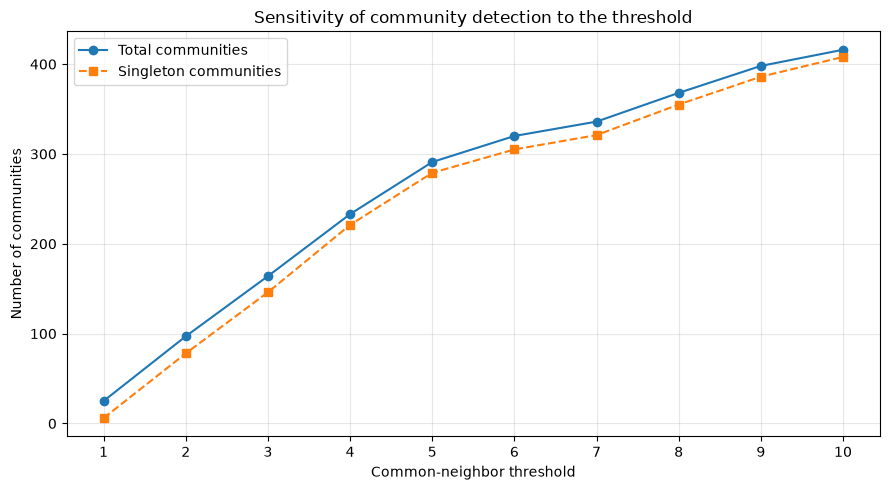

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Communities"],
    "o-", label="Total communities"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Singletons"],
    "s--", label="Singleton communities"
)

plt.xlabel("Common-neighbor threshold")
plt.ylabel("Number of communities")
plt.title("Sensitivity of community detection to the threshold")
plt.xticks(list(thresholds))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### 2.3. Selecting the Similarity Threshold

The common-neighbor estimator requires a threshold $\tau$ to determine which pairs of vertices should be grouped together. Our initial experiments show that the estimated number of communities is highly sensitive to this choice. Therefore, we introduce a systematic selection procedure based on modularity.

Modularity measures whether a partition contains more edges within communities than would be expected under a random network model preserving the vertex degrees. For an undirected graph, modularity is defined as

$$
Q=\frac{1}{2m}\sum_{i,j}
\left(A_{ij}-\frac{k_i k_j}{2m}\right)
\delta(c_i,c_j),
$$

where $m$ is the number of edges, $A_{ij}$ is the adjacency matrix, $k_i$ denotes the degree of vertex $i$, and $\delta(c_i,c_j)$ equals 1 when vertices $i$ and $j$ belong to the same community.

For each candidate threshold, we construct the common-neighbor similarity graph and obtain its connected components. We then calculate the modularity of this partition on the original graph, rather than on the similarity graph. The threshold producing the highest modularity is selected.

This approach allows us to select the threshold using only the observed network, without requiring knowledge of its true community structure. However, maximizing modularity may favor larger communities and fail to identify smaller groups. We will investigate this limitation using stochastic block models with known planted communities.


In [42]:
# Select the common-neighbour threshold using modularity

def select_threshold(G, thresholds=range(1, 11)):
    results = []

    nodes = list(G.nodes())

    for t in thresholds:
        n_comm, labels = estimate_communities(G, threshold=t)

        # Convert labels into sets of vertices
        communities = [
            {nodes[i] for i in np.where(labels == c)[0]}
            for c in range(n_comm)
        ]

        # Evaluate partition on the original network
        Q = nx.community.modularity(G, communities)

        sizes = np.bincount(labels)

        results.append({
            "Threshold": t,
            "Communities": n_comm,
            "Modularity": Q,
            "Singletons": np.sum(sizes == 1)
        })

    results = pd.DataFrame(results)

    best_index = results["Modularity"].idxmax()
    best_threshold = int(results.loc[best_index, "Threshold"])

    return best_threshold, results


best_t, selection_results = select_threshold(
    weaver, thresholds=range(1, 11)
)

print(f"Selected threshold: {best_t}")
display(selection_results.round(4))


Selected threshold: 1


,Threshold,Communities,Modularity,Singletons
0,1,25,0.8534,6
1,2,97,0.7966,78
2,3,164,0.7063,146
3,4,233,0.5813,221
4,5,291,0.4561,279
5,6,320,0.3745,305
6,7,336,0.3249,321
7,8,368,0.2055,355
8,9,398,0.1022,386
9,10,416,0.0680,408


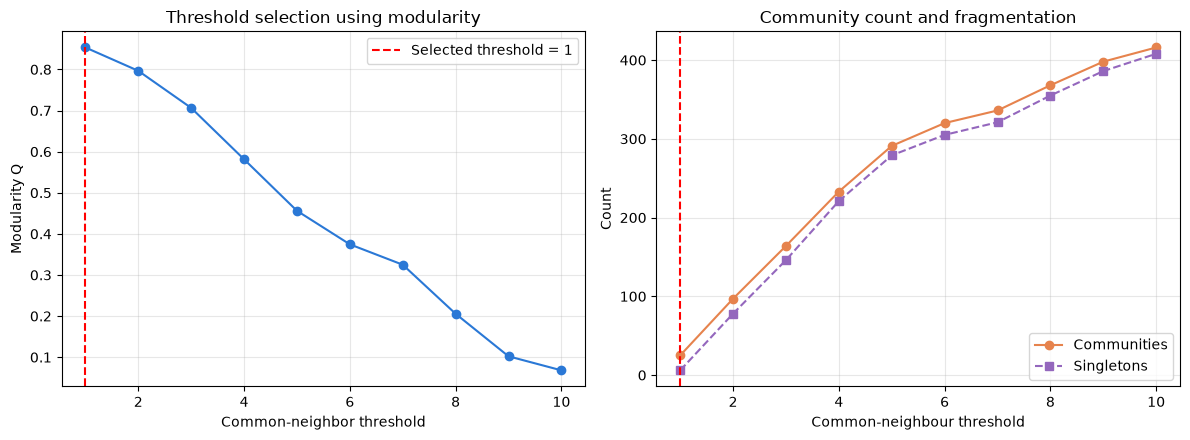

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(
    selection_results["Threshold"],
    selection_results["Modularity"],
    "o-", color="#2a78d6"
)

axes[0].axvline(
    best_t, color="red", linestyle="--",
    label=f"Selected threshold = {best_t}"
)

axes[0].set_xlabel("Common-neighbor threshold")
axes[0].set_ylabel("Modularity Q")
axes[0].set_title("Threshold selection using modularity")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    selection_results["Threshold"],
    selection_results["Communities"],
    "o-", color="#e6834d",
    label="Communities"
)

axes[1].plot(
    selection_results["Threshold"],
    selection_results["Singletons"],
    "s--", color="#9467bd",
    label="Singletons"
)

axes[1].axvline(best_t, color="red", linestyle="--")

axes[1].set_xlabel("Common-neighbour threshold")
axes[1].set_ylabel("Count")
axes[1].set_title("Community count and fragmentation")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 2.4. Validation Using Stochastic Block Models

To evaluate the effectiveness of our community-count estimator, we test it on networks generated using the stochastic block model (SBM). This model allows us to construct graphs with a known number of planted communities and control how strongly these communities are separated.

We consider SBMs with $K$ equally sized communities. Two vertices within the same community are connected independently with probability $p_{\mathrm{in}}$, while vertices belonging to different communities are connected with probability $p_{\mathrm{out}}$.

When $p_{\mathrm{in}} > p_{\mathrm{out}}$, edges are more likely to occur within communities than between them. Increasing the difference between these probabilities generally makes the planted community structure easier to identify.

For each generated network, we apply our common-neighbor estimator, automatically select the similarity threshold by maximizing modularity, and compare the estimated number of communities $\hat K$ with the planted number $K$.

We investigate how estimation accuracy changes with the number of communities and the strength of their separation. Repeated simulations are used to assess the stability of the estimator and identify situations in which it fails.


In [44]:
# Generate and test stochastic block models

SBM_K_VALUES = [2, 4, 6]
SBM_SEPARATIONS = {
    "Weak": 0.04,
    "Moderate": 0.10,
    "Strong": 0.20
}

SBM_N = 240
SBM_P_OUT = 0.01
SBM_REPS = 10

rng_sbm = np.random.default_rng(SEED)

def generate_sbm(K, p_in, p_out, n=240, seed=None):
    sizes = [n // K] * K
    probabilities = np.full((K, K), p_out)
    np.fill_diagonal(probabilities, p_in)

    return nx.stochastic_block_model(
        sizes, probabilities, seed=seed
    )

sbm_results = []

for K in SBM_K_VALUES:
    for separation, p_in in SBM_SEPARATIONS.items():
        for rep in range(SBM_REPS):

            G = generate_sbm(
                K, p_in, SBM_P_OUT,
                n=SBM_N,
                seed=int(rng_sbm.integers(0, 2**31))
            )

            best_t_sbm, _ = select_threshold(
                G, thresholds=range(1, 11)
            )

            K_hat, labels = estimate_communities(
                G, threshold=best_t_sbm
            )

            sbm_results.append({
                "Planted K": K,
                "Separation": separation,
                "p_in": p_in,
                "Estimated K": K_hat,
                "Selected threshold": best_t_sbm,
                "Absolute error": abs(K_hat - K)
            })

sbm_df = pd.DataFrame(sbm_results)

summary_sbm = (
    sbm_df.groupby(["Separation", "Planted K"])
    .agg(
        Mean_estimated_K=("Estimated K", "mean"),
        Std_estimated_K=("Estimated K", "std"),
        Mean_absolute_error=("Absolute error", "mean")
    )
    .round(2)
)

display(summary_sbm)


Mean_estimated_K  Std_estimated_K  Mean_absolute_error
Separation Planted K                                                        
Moderate   2                     135.4            31.45                133.4
           4                     113.3            15.94                109.3
           6                     150.2            75.38                144.2
Strong     2                       2.4             0.70                  0.4
           4                      25.2            12.36                 21.2
           6                      82.1            14.75                 76.1
Weak       2                      57.7             9.92                 55.7
           4                      83.3            83.79                 79.9
           6                      44.9            79.99                 39.7

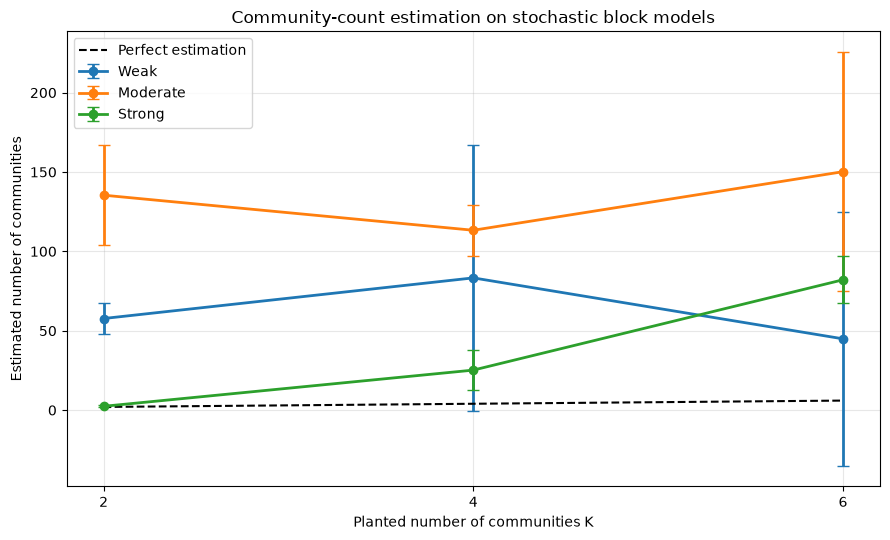

In [45]:
# Estimated versus planted number of communities

fig, ax = plt.subplots(figsize=(9, 5.5))

for separation in SBM_SEPARATIONS:
    subset = (
        sbm_df[sbm_df["Separation"] == separation]
        .groupby("Planted K")["Estimated K"]
        .agg(["mean", "std"])
    )

    ax.errorbar(
        subset.index,
        subset["mean"],
        yerr=subset["std"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=separation
    )

ax.plot(
    SBM_K_VALUES, SBM_K_VALUES,
    "k--", label="Perfect estimation"
)

ax.set_xlabel("Planted number of communities K")
ax.set_ylabel("Estimated number of communities")
ax.set_title("Community-count estimation on stochastic block models")
ax.set_xticks(SBM_K_VALUES)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


### 2.5. Preliminary Results and Limitations

The stochastic block model experiments reveal that our common-neighbor estimator frequently overestimates the planted number of communities. Although it performs reasonably well for two strongly separated communities, its accuracy deteriorates when the number of communities increases or when the separation is weaker.

A likely explanation is excessive fragmentation of the similarity graph. Vertices that do not share enough common neighbors with other vertices become isolated components, which are subsequently counted as separate communities. This effect is particularly problematic in sparse networks, where common-neighbor counts are generally small.

These results demonstrate that maximizing modularity over the tested thresholds does not necessarily recover the true community count. Further experiments can be done to look into the effect of singleton communities on our community detection procedure. Moreover, it might be interesting to consider different methods for the selection of the threshold $\tau$.

whether degree-normalized similarities or alternative grouping procedures can improve estimation accuracy.


## 3. Empirical Testing on Real-Life Network

### 3.1. Weaver Social Interaction Network

For our choice of network, we decided on `aver-weaver-social`, in which network:

- Nodes represent individual birds
- Edges represent observed social interactions

Due to the nature of this network we would expect naturally communities to occur due to geographical reasons and genetical or familial relations. Likely communities would represent:

- Different bird flocks or family groups *(social structure)*
- Potential kinship groups or breeding pairs *(bloodline relation)*
- Birds that spend time together in the same territory *(geographical proximity)*

### 3.2. Network Properties Analysis

In [37]:
def describe_network(G, name):
    degree_list = np.array([deg for _, deg in G.degree()])
    print(f"Computing network {name}")
    return {"network": name, "n": G.number_of_nodes(), "m": G.number_of_edges(),
            "mean degree": degree_list.mean(), "max degree": int(degree_list.max()),
            "leaves": int((degree_list == 1).sum()),
            "isolated vertices": int((degree_list == 0).sum()),
            "interactions": nx.number_connected_components(G),
            "avg clustering coeff.": nx.average_clustering(G),
            "assortativity": nx.degree_assortativity_coefficient(G),
            "transitivity": nx.transitivity(G)}

display(pd.DataFrame([describe_network(weaver, "Social Weaver Network")]).set_index("network"))

Computing network Social Weaver Network


,n,m,mean degree,max degree,leaves,isolated vertices,interactions,avg clustering coeff.,assortativity,transitivity
network,,,,,,,,,,
Social Weaver Network,445,1332,5.986517,27,41,0,22,0.668505,0.199066,0.588094


### 3.3 Predictions Based on Network Properties

-> global clustering coefficient


Community detection

We estimate the community sizes based on the method from problem 1, and implement spectral clustering

In [38]:

M = common_neighbor_matrix(G)

threshold, estimated_communities = select_threshold(G)
K_estimated = len(estimated_communities)

print("Selected threshold:", threshold)
print("Estimated number of communities:", K_estimated)
print("Estimated community sizes:", sorted([len(c) for c in estimated_communities]))

Selected threshold: 7
Estimated number of communities: 10
Estimated community sizes: [9, 10, 10, 11]


### 3.4 Spectral Clustering Implementation

In [ ]:
nodes = list(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)

spectral = SpectralClustering(n_clusters=K_estimated, affinity="precomputed", assign_labels="kmeans",n_init=20)

spectral_labels = spectral.fit_predict(A)

spectral_communities = [{nodes[i] for i in range(len(nodes)) if spectral_labels[i] == c} for c in range(K_estimated)]

print("Spectral clustering")
print("Number of communities:", len(spectral_communities))
print("Community sizes:", sorted([len(c) for c in spectral_communities], reverse=True))

Spectral clustering
Number of communities: 10
Community sizes: [39, 39, 28, 27, 22, 21, 19, 18, 14, 13]


### 3.5. Louvain Implementation

(Louvain) Number of communities: 6
(Louvain) Community sizes: [41, 41, 40, 40, 39, 39]


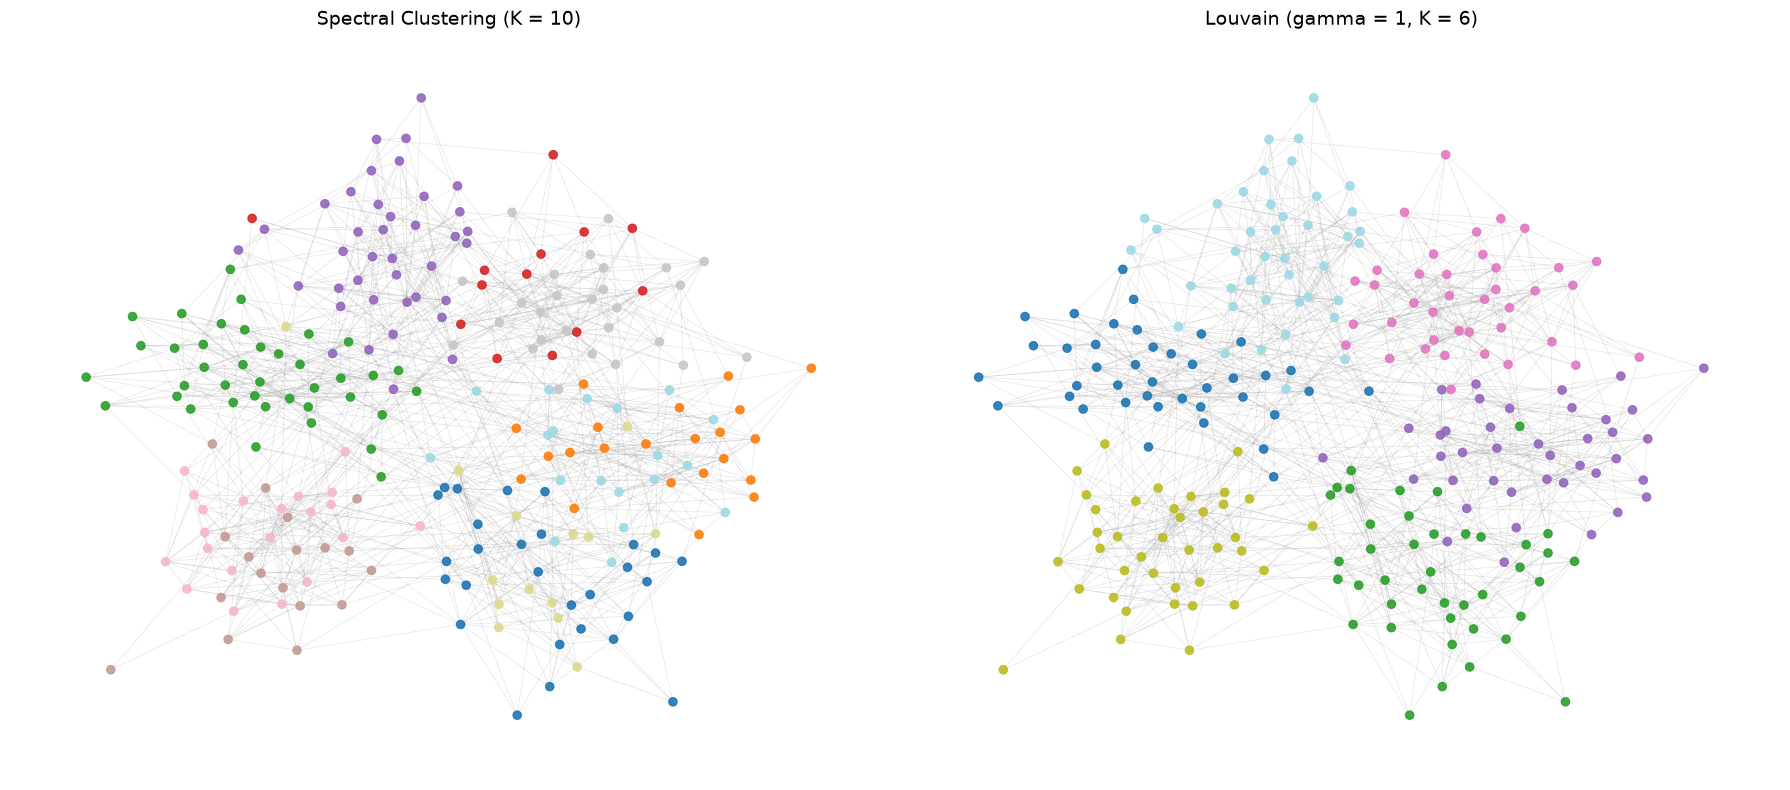

In [41]:
louvain_communities = [set(c) for c in nx.community.louvain_communities(G)]

def make_label_dict(communities, nodes):
    """Create mapping that labels nodes according to a given community partition."""
    label_dict = {}
    for idx, comm in enumerate(communities):
        for v in comm:
            label_dict[v] = idx
    uncovered = [v for v in nodes if v not in label_dict]
    if uncovered:
        raise ValueError(
            f"{len(uncovered)} node(s) not covered by the partition, "
            f"e.g. {uncovered[:5]}"
        )
    return label_dict

def node_color_list(label_dict, nodes, cmap_name="tab20"):
    """Define a colour list which returns a colour for each community."""
    n_comm = max(label_dict.values()) + 1
    palette = plt.get_cmap(cmap_name, n_comm)   # n_comm discrete colours
    return [palette(label_dict[v]) for v in nodes]

nodes = list(G.nodes())

# spectral_communities from 3.4. Spectral Clustering Implementation
spectral_label_by_node = make_label_dict(spectral_communities, nodes)
louvain_label_by_node  = make_label_dict(louvain_communities, nodes)


print("(Louvain) Number of communities:", len(louvain_communities))
print("(Louvain) Community sizes:",sorted([len(c) for c in louvain_communities], reverse=True))

pos = nx.spring_layout(G, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

partitions = [
    (axes[0], spectral_label_by_node, f"Spectral Clustering (K = {len(spectral_communities)})"),
    (axes[1], louvain_label_by_node, f"Louvain (gamma = 1, K = {len(louvain_communities)})"),
]

for ax, labels, title in partitions:
    # node_colors = [labels[node] for node in G.nodes()]
    node_colors = node_color_list(labels, nodes)

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        alpha=0.2,
        width=0.5,
        edge_color="gray"
    )

    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_color=node_colors,
        node_size=35,
        alpha=0.9
    )

    # nx.draw_networkx_nodes(G, pos, ax=ax,node_color=node_colors, cmap="tab20", node_size=35,alpha=0.9)

    ax.set_title(title, fontsize=14)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
### Resolution sweep for Louvain (defines gamma_df) ###

GAMMA_GRID = np.linspace(0.1, 2.0, 20)
gamma_results = []

for gamma in GAMMA_GRID:
    louvain_gamma = nx.community.louvain_communities(G, resolution=float(gamma), seed=SEED)
    louvain_sets = [set(c) for c in louvain_gamma]
    sizes = np.array([len(c) for c in louvain_sets])

    gamma_results.append({
        "gamma": float(gamma),
        "num_communities": len(louvain_sets),
        "mean_size": sizes.mean(),
        "size_std": sizes.std(),
        "modularity": nx.community.modularity(G, louvain_sets),  # Q at gamma = 1, see note
    })

gamma_df = pd.DataFrame(gamma_results)
display(gamma_df.round(3))

,gamma,num_communities,mean_size,size_std,modularity
0,0.1,1,240.0,0.000,0.000
1,0.2,1,240.0,0.000,0.000
2,0.3,4,60.0,20.000,0.563
3,0.4,6,40.0,0.577,0.641
4,0.5,6,40.0,0.577,0.641
5,0.6,6,40.0,0.577,0.641
6,0.7,6,40.0,0.577,0.641
7,0.8,6,40.0,0.577,0.641
8,0.9,6,40.0,0.577,0.641
9,1.0,6,40.0,0.577,0.641


### 3.6. Agreement Metric

$$\mu(\mathcal{C}, \mathcal{C'}) = \frac{\sum_{\gamma \in \Gamma} \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C}) \times \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C'})}{\sqrt{\sum_{\gamma \in \Gamma} \left( \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C}) \right)^2 \times \sqrt{\sum_{\gamma \in \Gamma} \left( \mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C'}) \right)^2}}}$$

where $\mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C})$ is the configuration model modularity, given by:

$$\mathcal{M}^{\operatorname{CM}}(\gamma, \mathcal{C}) \coloneqq \frac{1}{2|E|} \sum_{i = 1}^{k} \sum_{v, w \in C_i} \left( I_{vw} - \gamma \frac{d_v d_w}{2|E|} \right)$$

In [ ]:
### Define Configuration Model Modularity ###

def validate_partition(G, communities):
    """Ensure communities is a genuine partition of V(G)"""
    seen = set()
    for comm in communities:
        comm = set(comm)
        overlap = seen & comm
        if overlap:
            raise ValueError(f"Partition overlaps on {sorted(overlap)[:5]} ...")
        seen |= comm
    missing = set(G.nodes()) - seen
    if missing:
        raise ValueError(f"Partition misses {len(missing)} nodes, e.g. {sorted(missing)[:5]}")


def configuration_modularity(G, communities, gamma=1.0):
    """
    Configuration model modularity at resolution gamma.
    Calculated as a - gamma * b, where 
        a = (sum over all communities of {# intra-community edges}) / (total # of edges)
        b = sum over all communities of {[(sum of all community degrees) / [2 * (total # of edge)]^2}
    """
    m = G.number_of_edges()
    if m == 0:
        raise ValueError("Modularity is undefined for a graph with no edges.")
    validate_partition(G, communities)

    degree = dict(G.degree())
    a = 0.0
    b = 0.0
    for comm in communities:
        members = set(comm)
        K_c = sum(degree[v] for v in members)
        m_c = G.subgraph(members).number_of_edges()   # internal edges, counted once
        a += m_c / m
        b += (K_c / (2.0 * m)) ** 2
    return a - gamma * b

_check = [set(c) for c in nx.community.louvain_communities(G, seed=SEED)]

manual_q = configuration_modularity(G, _check, gamma=1.0)
nx_q = nx.community.modularity(G, _check)

print(f"manual  Q (gamma=1) = {manual_q:.8f}")
print(f"networkx Q (gamma=1) = {nx_q:.8f}")
print(f"absolute difference = {abs(manual_q - nx_q):.2e}")

manual  Q (gamma=1) = 0.64060503
networkx Q (gamma=1) = 0.64060503
absolute difference = 1.11e-16


In [ ]:
### Agreement Metric Implementation ###

GAMMAS = np.linspace(0.05, 2.5, 250) # range of gammas in the set Г

def modularity_vec(G, communities, gammas=GAMMAS):
    """Vector of M^CM(gamma, C) over the premissible values for gamma in GAMMAS."""
    return np.array([configuration_modularity(G, communities, g) for g in gammas], dtype=float)

def mu(G, partition_a, partition_b, gammas=GAMMAS):
    """
    Agreement metric, given by the cosine similarity of the modularities over gammas for the two partitions.
    
    mu(C, C') = <p(C), p(C')> / (||p(C)|| * ||p(C')||)
    """
    modularities_a = modularity_vec(G, partition_a, gammas) # modularities of partition a over gammas
    modularities_b = modularity_vec(G, partition_b, gammas) # modularities of partition b over gammas
    denominator = np.linalg.norm(modularities_a) * np.linalg.norm(modularities_b)
    if denominator == 0.0:
        return np.nan
    numerator = np.dot(modularities_a, modularities_b)
    return float(numerator / denominator)

,Spectral (K-hat),Louvain (gamma=1),Louvain (gamma=1.70)
Spectral (K-hat),1.0000,0.9993,0.9993
Louvain (gamma=1),0.9993,1.0000,1.0000
Louvain (gamma=1.70),0.9993,1.0000,1.0000


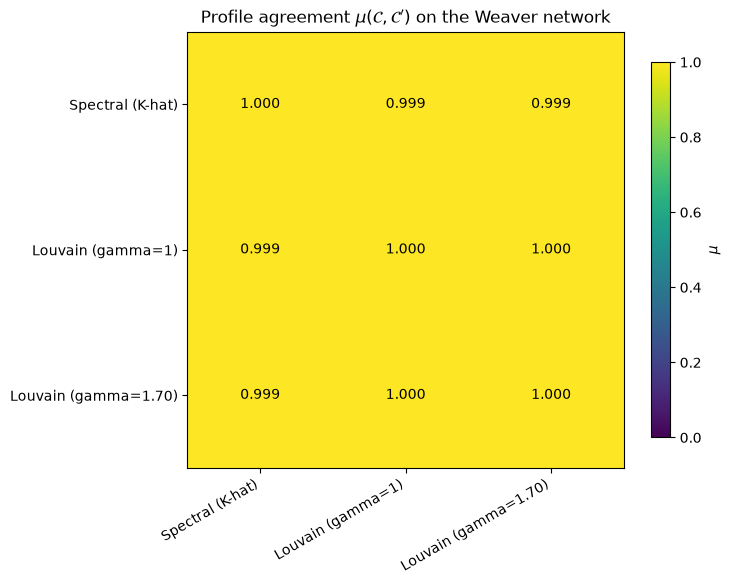

In [ ]:
### Applying mu to the Weaver network ###

# Louvain at the modularity-selected resolution (from the gamma sweep)
OPTIMAL_GAMMA = float(gamma_df.loc[gamma_df["modularity"].idxmax(), "gamma"])
louvain_selected = [set(c) for c in
                    nx.community.louvain_communities(G, resolution=OPTIMAL_GAMMA, seed=SEED)]

named_partitions = {
    "Spectral (K-hat)": [set(c) for c in spectral_communities],
    "Louvain (gamma=1)": [set(c) for c in louvain_communities],
    f"Louvain (gamma={OPTIMAL_GAMMA:.2f})": louvain_selected,
}

# MU Matrix for Comparison of Different Partition Methods
names = list(named_partitions)
MU = np.eye(len(names))
for i, ni in enumerate(names):
    for j, nj in enumerate(names):
        if j > i:
            MU[i, j] = MU[j, i] = mu(G, named_partitions[ni], named_partitions[nj])

mu_df = pd.DataFrame(MU, index=names, columns=names)
display(mu_df.round(4))

# Heatmap Visualization of Method Comparison
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(mu_df.values, vmin=0.0, vmax=1.0, cmap="viridis")
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_yticklabels(names)

for i in range(len(names)):
    for j in range(len(names)):
        val = mu_df.values[i, j]
        ax.text(j, i, f"{val:.3f}", ha="center", va="center",
                color="white" if val < 0.65 else "black", fontsize=10)

ax.set_title(r"Profile agreement $\mu(\mathcal{C},\mathcal{C}')$ on the Weaver network")
fig.colorbar(im, ax=ax, label=r"$\mu$", shrink=0.85)
plt.tight_layout()
plt.show()